In [1]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2




r_seed = 42

WORKDIR = 'C:/Users/cristiano.nascimento/git/LSTM_giroscopio_acelerometro'
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/Code/DataPrep/"+data_hora

C:\Users\cristiano.nascimento\AppData\Local\Temp\ipykernel_23620\847897453.py:15: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  from kerastuner.tuners import RandomSearch
c:\Users\cristiano.nascimento\git\LSTM_giroscopio_acelerometro\.venv\lib\site-packages\tensorflow_addons\utils\tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(


In [2]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [3]:
## get dataset
pd.set_option("display.precision", 9)

# select only sensor data from smart watches
data = pd.read_csv(WORKDIR+'/Code/DataPrep/activity_recognition_data_watch_concat_by_comparacao_grupos.csv',dtype={"value": "float64"})

In [4]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904


In [5]:
data.isnull().sum()

pessoa_x              0
atividade             0
tempo_acelerômetro    0
acelerômetro_x        0
acelerômetro_Y        0
acelerômetro_Z        0
tempo_gyro            0
giroscópio_x          0
giroscópio_Y          0
giroscópio_Z          0
dtype: int64

In [6]:
#remove the null class
data=data.dropna()

# **Data Exploration**

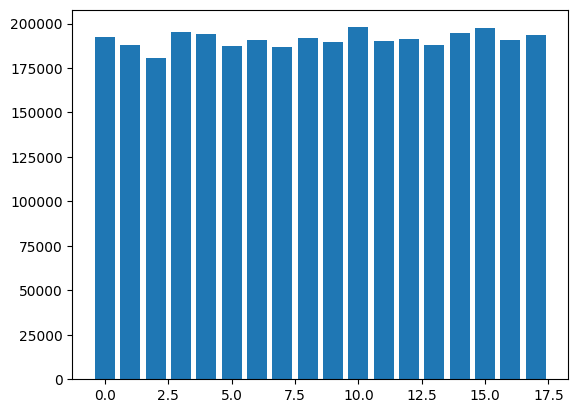

In [7]:
## the distribution of output classes
plt.bar(data["atividade"].value_counts().index, data["atividade"].value_counts().values)
plt.show()

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

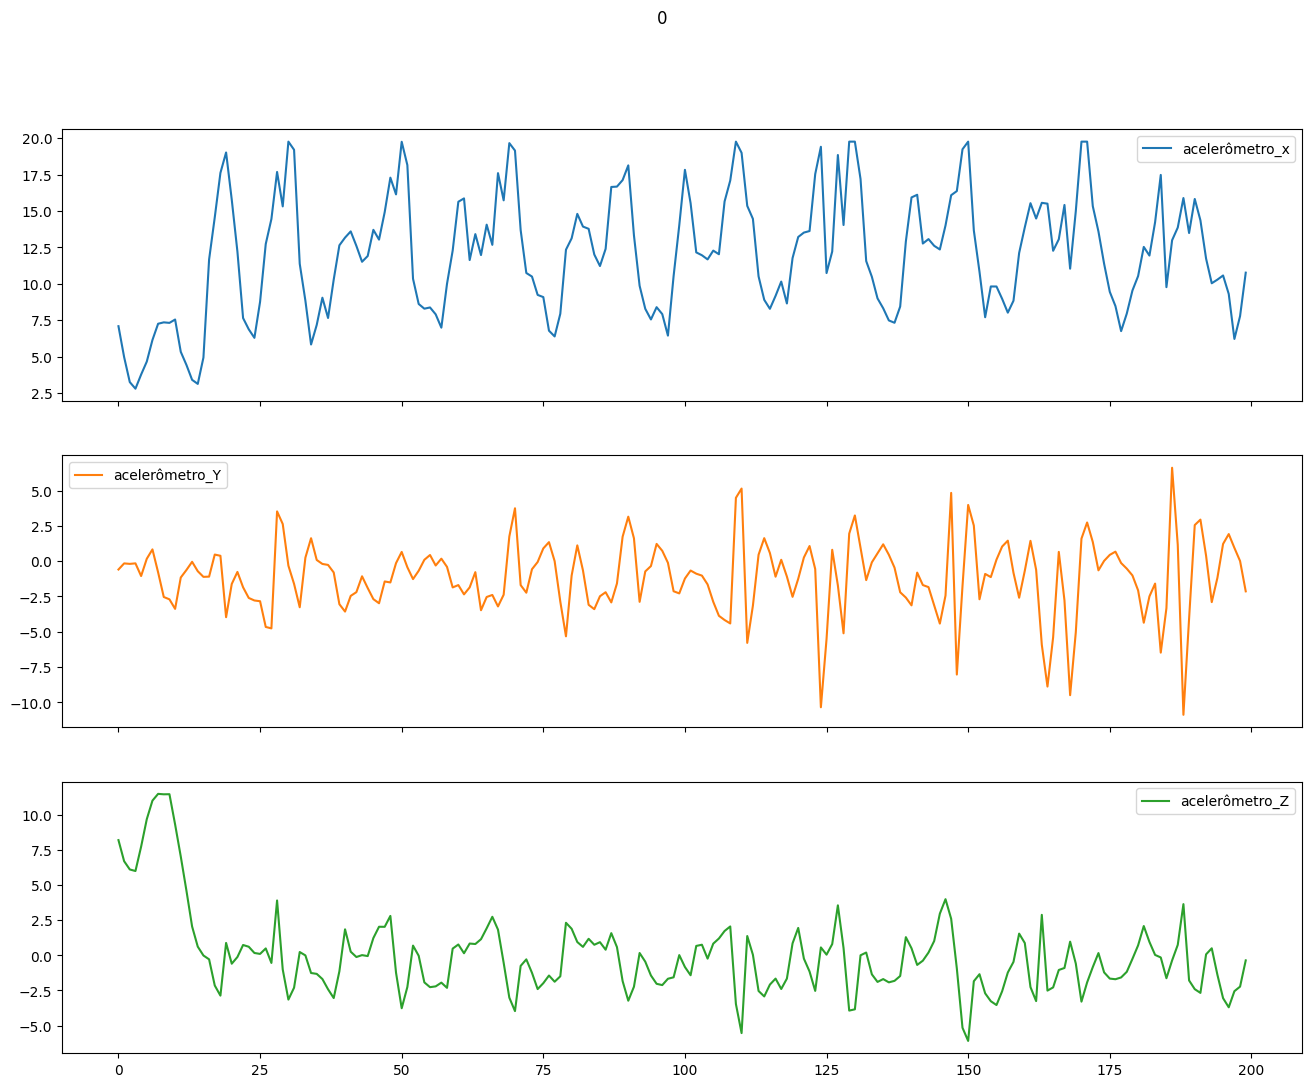

In [8]:
## x,y,z vaues for activity 'sit' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['acelerômetro_x','acelerômetro_Y','acelerômetro_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

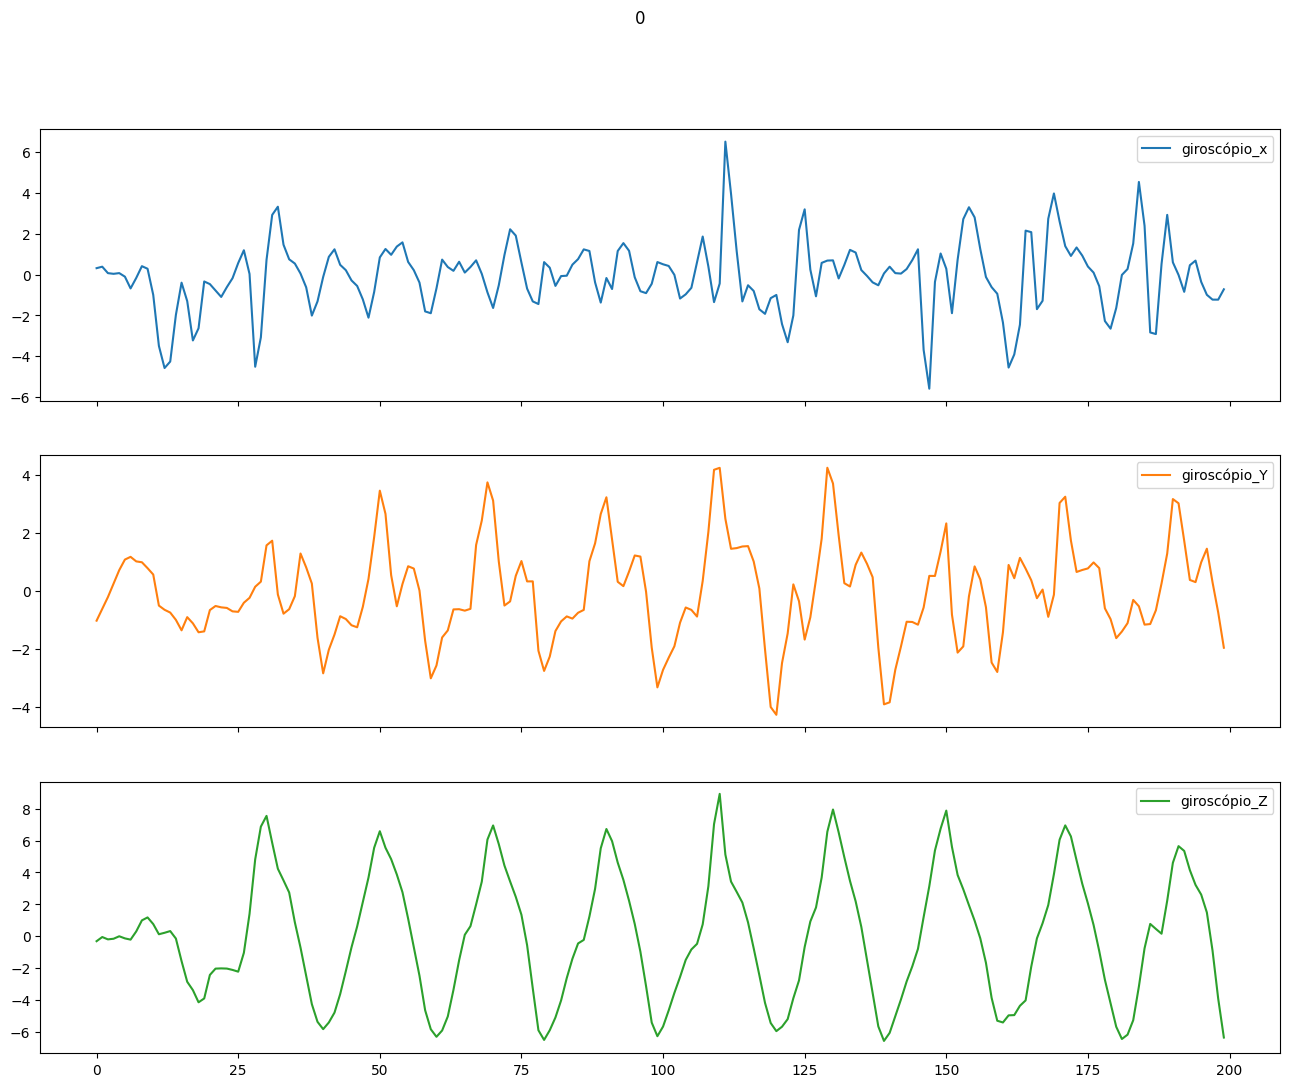

In [9]:
## x,y,z vaues for activity 'stand' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['giroscópio_x','giroscópio_Y','giroscópio_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

In [10]:
data = data[data.pessoa_x!=1629]

In [11]:
data.pessoa_x.unique()

array([1600, 1601, 1602, 1603, 1604, 1605, 1606, 1607, 1608, 1609, 1610,
       1611, 1612, 1613, 1614, 1615, 1616, 1617, 1618, 1619, 1620, 1621,
       1622, 1623, 1624, 1625, 1626, 1627, 1628, 1630, 1631, 1632, 1633,
       1634, 1635, 1636, 1637, 1638, 1639, 1640, 1641, 1642, 1643, 1644,
       1645, 1646, 1647, 1648, 1649, 1650], dtype=int64)

In [12]:
data = data.reset_index(drop=True)

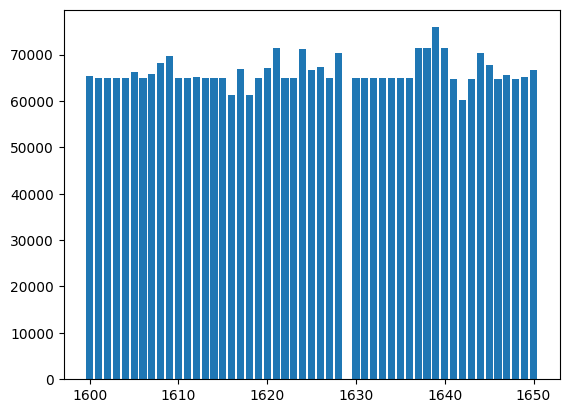

In [13]:
## number of events per user

plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [14]:
#selecting only activities 0 to 3
#data = data[data["atividade"].isin([0,1,2,3,13,16])]

In [15]:
# Define the mapping dictionary
#mapping_dict = {13:4,16:5}

In [16]:
#data["atividade"] = data["atividade"].replace(to_replace=mapping_dict)

In [17]:
data.shape

(3310585, 10)

In [18]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904


In [19]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904


In [20]:
data.shape

(3310585, 10)

In [21]:
grouped_data = data.groupby(['pessoa_x'])['atividade'].value_counts().unstack()

In [22]:
print(grouped_data)

atividade      0       1       2       3       4       5       6       7   \
pessoa_x                                                                    
1600       3603.0  3604.0  3604.0  3604.0  3604.0  3604.0  3603.0  3603.0   
1601       3601.0  3602.0  3601.0  3601.0  3602.0  3601.0  3602.0  3602.0   
1602       3603.0  3603.0  3603.0  3603.0  3699.0  3603.0  3603.0  3603.0   
1603       3603.0  3602.0  3602.0  3603.0  3601.0  3601.0  3602.0  3602.0   
1604       3603.0  3603.0  3604.0  3603.0  3603.0  3617.0  3603.0  3603.0   
1605       3603.0  3603.0  3602.0  3602.0  3602.0  3602.0  3615.0  3602.0   
1606       3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0   
1607       3603.0  3602.0  3602.0  3601.0  3602.0  3602.0  3601.0  3602.0   
1608       3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3609.0   
1609       3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0   
1610       3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0   

In [23]:
nan_values = grouped_data[grouped_data.isnull().any(axis=1)].index

In [24]:
nan_values_array = nan_values.to_numpy()

In [25]:
print(nan_values)

Index([1616, 1618, 1637, 1638, 1639, 1640, 1642], dtype='int64', name='pessoa_x')


In [26]:
data = data[~data['pessoa_x'].isin([1616, 1618, 1637, 1638, 1639,1640, 1642])]

In [27]:
grouped_data2 = data.groupby(['pessoa_x'])['atividade'].value_counts().unstack()

In [28]:
print(grouped_data2)

atividade    0     1     2     3     4     5     6     7     8     9     10  \
pessoa_x                                                                      
1600       3603  3604  3604  3604  3604  3604  3603  3603  3604  3603  3604   
1601       3601  3602  3601  3601  3602  3601  3602  3602  3602  3602  3601   
1602       3603  3603  3603  3603  3699  3603  3603  3603  3603  3603  3603   
1603       3603  3602  3602  3603  3601  3601  3602  3602  3601  3619  3602   
1604       3603  3603  3604  3603  3603  3617  3603  3603  3604  3603  3603   
1605       3603  3603  3602  3602  3602  3602  3615  3602  4935  3603  3601   
1606       3603  3603  3603  3603  3603  3603  3603  3603  3603  3603  3603   
1607       3603  3602  3602  3601  3602  3602  3601  3602  3602  3602  3602   
1608       3603  3603  3603  3603  3603  3603  3603  3609  3603  6899  3603   
1609       3603  3603  3603  3603  3603  3603  3603  3603  3603  3603  6070   
1610       3603  3603  3603  3603  3603  3603  3603 

# **Models**

In [29]:
def delete_segments_not_fully_filled(df_data_windowed,df_label_windowed):
    indexes = np.where(df_label_windowed == -1)[0]
    unique_arr = np.unique(indexes, return_index=True)[0]
    new_df_label_windowed = np.delete(df_label_windowed,unique_arr,axis=0)
    new_df_data_windowed = np.delete(df_data_windowed,unique_arr,axis=0)
    return (new_df_data_windowed,new_df_label_windowed)

In [30]:
def apply_segmentation_no_sliding_window(df_data):
# Define window size and step size
    window_size = 200
    step_size = 20

    # Calculate number of windows
    n_windows = int((df_data.shape[0] / window_size))

    # Create segmented data using sliding window
    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        #populate the 3d array only if the 200 segment has the value in label
        label_consistency = (df_data[['atividade']][start_idx:end_idx].nunique()==1) 
        if label_consistency[0] == True:
            segments[i] = df_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [31]:
def apply_segmentation_with_sliding_window(df_data):
    #creating sliding window for train data
    import numpy as np

    window_size = 200
    step_size = 20

    n_windows = int((df_data.shape[0] - window_size) // step_size + 1)

    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * step_size
        end_idx = start_idx + window_size
        label_consistency = df_data[['atividade']][start_idx:end_idx].nunique()==1
        if label_consistency[0] == True:
            segments[i] = df_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [32]:
print(data.pessoa_x.unique())

[1600 1601 1602 1603 1604 1605 1606 1607 1608 1609 1610 1611 1612 1613
 1614 1615 1617 1619 1620 1621 1622 1623 1624 1625 1626 1627 1628 1630
 1631 1632 1633 1634 1635 1636 1641 1643 1644 1645 1646 1647 1648 1649
 1650]


In [33]:
X_test_data = data[data['pessoa_x'].isin([1600,1601, 1602, 1603, 1604])]

In [34]:
print(X_test_data.shape)

(324933, 10)


In [35]:
X_test_data = X_test_data.reset_index(drop = True)

In [36]:
X_test_data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904


In [37]:
X_test_data.tail()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
324928,1604,17,696162901396854,9.5715690,-0.041449618,3.2872388,696162951320494,0.3106676,0.66342163,0.286358270
324929,1604,17,696162951320494,10.8524680,-4.437204000,7.8601640,696163001244134,1.1554223,-0.19837727,-0.010850517
324930,1604,17,696163001244134,6.6434608,-0.333542230,3.4404678,696163051167774,1.2757971,0.53985095,0.401406820
324931,1604,17,696163051167774,8.1805380,-2.035819500,7.4268136,696163101091414,0.1636611,0.23412009,0.454670040
324932,1604,17,696163101091414,7.9028110,-1.219396800,8.5975780,696163151015054,-0.4648449,0.92654200,0.722051400


In [38]:
X_test_data.pessoa_x.unique()

array([1600, 1601, 1602, 1603, 1604], dtype=int64)

In [39]:
print(f"percentage of validation is {X_test_data.shape[0]/data.shape[0]}")

percentage of validation is 0.11450059693540271


In [40]:
X_test_data['atividade'].value_counts()

atividade
17    18584
4     18109
9     18030
5     18026
3     18014
2     18014
8     18014
1     18014
12    18014
6     18013
7     18013
10    18013
13    18013
16    18013
0     18013
11    18012
14    18012
15    18012
Name: count, dtype: int64

In [41]:
X_test_data = X_test_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','atividade']]

In [42]:
X_train_validation_data = data[~data.pessoa_x.isin([1600,1601, 1602, 1603, 1604])]

In [43]:
print(X_train_validation_data.shape)

(2512895, 10)


In [44]:
X_train_validation_data = X_train_validation_data.reset_index(drop = True)

In [45]:
X_train_validation_data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1605,0,9914136743005,6.7535940,-4.7649100,0.6823475,9914136743005,-1.06786870,0.08446269,-0.7974660
1,1605,0,9914186746890,7.3018660,-4.1160817,0.7445967,9914186746890,-0.99969180,-0.14563443,-0.7260933
2,1605,0,9914236752414,7.6107183,-3.8407485,1.1133038,9914236752414,-0.60447870,-0.17759237,-0.6366111
3,1605,0,9914286674776,8.9993550,-3.9867947,1.0702082,9914286674776,-0.55228070,-0.25642192,-0.5098446
4,1605,0,9914336690902,10.9961195,-3.7545571,0.7206547,9914336690902,-0.49582174,-0.22765979,-0.4651035


In [46]:
X_train_validation_data.tail()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
2512890,1650,17,2426184321449912,4.7689505,-5.4014688,7.5842323,2426184371437252,-2.8560646,2.0571015,0.85393304
2512891,1650,17,2426184371437252,2.1377227,-7.2114854,8.0654670,2426184421424592,-2.9114583,1.8174170,1.28110410
2512892,1650,17,2426184421424592,1.4865000,-13.3023340,5.3552310,2426184471411932,-3.0158541,1.5500356,2.05768180
2512893,1650,17,2426184471411932,4.0171714,-13.1467110,5.1182046,2426184521399272,-3.2182543,1.5958420,3.01855040
2512894,1650,17,2426184521399272,4.4122143,-15.3182530,3.3704374,2426184571385262,-2.4555252,0.8661359,3.35410860


In [47]:
X_train_validation_data.pessoa_x.unique()

array([1605, 1606, 1607, 1608, 1609, 1610, 1611, 1612, 1613, 1614, 1615,
       1617, 1619, 1620, 1621, 1622, 1623, 1624, 1625, 1626, 1627, 1628,
       1630, 1631, 1632, 1633, 1634, 1635, 1636, 1641, 1643, 1644, 1645,
       1646, 1647, 1648, 1649, 1650], dtype=int64)

In [48]:
print(f"percentage of validation is {X_train_validation_data.shape[0]/data.shape[0]}")

percentage of validation is 0.8854994030645973


In [49]:
X_train_validation_data['atividade'].value_counts()

atividade
4     144592
10    144040
15    143526
13    141871
3     141178
14    140969
9     140177
2     139066
17    138923
0     138653
11    138239
8     138201
12    137654
7     137612
1     137548
16    136897
6     136882
5     136867
Name: count, dtype: int64

In [50]:
X_validation_data = X_train_validation_data[X_train_validation_data['pessoa_x'].isin([1605, 1606, 1607, 1608, 1609, 1610, 1611, 1612,1613])]

In [51]:
print(X_validation_data.shape)

(594470, 10)


In [52]:
X_validation_data = X_validation_data.reset_index(drop = True)

In [53]:
X_validation_data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1605,0,9914136743005,6.7535940,-4.7649100,0.6823475,9914136743005,-1.06786870,0.08446269,-0.7974660
1,1605,0,9914186746890,7.3018660,-4.1160817,0.7445967,9914186746890,-0.99969180,-0.14563443,-0.7260933
2,1605,0,9914236752414,7.6107183,-3.8407485,1.1133038,9914236752414,-0.60447870,-0.17759237,-0.6366111
3,1605,0,9914286674776,8.9993550,-3.9867947,1.0702082,9914286674776,-0.55228070,-0.25642192,-0.5098446
4,1605,0,9914336690902,10.9961195,-3.7545571,0.7206547,9914336690902,-0.49582174,-0.22765979,-0.4651035


In [54]:
X_validation_data.tail()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
594465,1613,17,614385745691914,2.9086560,-1.8427871,5.2896895,614385745691914,1.12878910,-0.8106092,0.056333315
594466,1613,17,614385795656394,2.1161750,-0.5978022,5.9840080,614385795656394,0.71333593,-1.0513590,-0.461385200
594467,1613,17,614385845620765,2.1449053,-1.4549265,5.6679730,614385845620765,0.14448474,-1.1749296,-0.875773100
594468,1613,17,614385895550220,1.9892824,-2.5466824,7.2888480,614385895550220,-0.57243824,-1.1376454,-1.166590200
594469,1613,17,614385945482455,6.1695585,-1.9792566,7.4277115,614385945482455,-0.21131358,-1.6116881,-1.195352400


In [55]:
X_validation_data.pessoa_x.unique()

array([1605, 1606, 1607, 1608, 1609, 1610, 1611, 1612, 1613], dtype=int64)

In [56]:
print(f"percentage of validation is {X_validation_data.shape[0]/X_train_validation_data.shape[0]}")

percentage of validation is 0.2365677833733602


In [57]:
X_validation_data['atividade'].value_counts()

atividade
9     35736
10    34890
11    33780
8     33757
13    33704
14    33013
12    32887
17    32441
6     32436
15    32432
7     32429
1     32425
2     32424
0     32424
5     32423
4     32423
3     32423
16    32423
Name: count, dtype: int64

In [58]:
X_validation_data = X_validation_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','atividade']]

In [59]:
X_train_data = X_train_validation_data[~X_train_validation_data.pessoa_x.isin([1605, 1606, 1607, 1608, 1609, 1610, 1611, 1612,1613])]

In [60]:
X_train_data.pessoa_x.unique()

array([1614, 1615, 1617, 1619, 1620, 1621, 1622, 1623, 1624, 1625, 1626,
       1627, 1628, 1630, 1631, 1632, 1633, 1634, 1635, 1636, 1641, 1643,
       1644, 1645, 1646, 1647, 1648, 1649, 1650], dtype=int64)

In [61]:
X_train_data.shape

(1918425, 10)

In [62]:
X_train_data = X_train_data.reset_index(drop=True)

In [63]:
print(f"percentage of validation is {X_train_data.shape[0]/X_train_validation_data.shape[0]}")

percentage of validation is 0.7634322166266397


In [64]:
X_train_data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1614,0,81605410362601,-1.5641619,1.6910546,8.6949920,81605459862601,0.57641697,-0.263993830,0.06649913
1,1614,0,81605459862601,-0.4317045,2.1004632,6.8873700,81605509362601,1.09413550,-0.037092507,-0.11885688
2,1614,0,81605509362601,-1.3295301,3.3526306,7.7421002,81605558862601,0.53487164,-0.044549357,-0.02085255
3,1614,0,81605558862601,-1.2624925,4.7843633,8.4675440,81605608362601,0.38679990,-0.090355730,-0.11246529
4,1614,0,81605608362601,-1.3774141,3.9009027,9.4036760,81605657862601,-0.22679240,-0.006199839,0.11337077


In [65]:
X_train_data.tail()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
1918420,1650,17,2426184321449912,4.7689505,-5.4014688,7.5842323,2426184371437252,-2.8560646,2.0571015,0.85393304
1918421,1650,17,2426184371437252,2.1377227,-7.2114854,8.0654670,2426184421424592,-2.9114583,1.8174170,1.28110410
1918422,1650,17,2426184421424592,1.4865000,-13.3023340,5.3552310,2426184471411932,-3.0158541,1.5500356,2.05768180
1918423,1650,17,2426184471411932,4.0171714,-13.1467110,5.1182046,2426184521399272,-3.2182543,1.5958420,3.01855040
1918424,1650,17,2426184521399272,4.4122143,-15.3182530,3.3704374,2426184571385262,-2.4555252,0.8661359,3.35410860


In [66]:
X_train_data = X_train_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','atividade']]

In [67]:
X_train_data.head()

,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,atividade
0,-1.5641619,1.6910546,8.6949920,0.57641697,-0.263993830,0.06649913,0
1,-0.4317045,2.1004632,6.8873700,1.09413550,-0.037092507,-0.11885688,0
2,-1.3295301,3.3526306,7.7421002,0.53487164,-0.044549357,-0.02085255,0
3,-1.2624925,4.7843633,8.4675440,0.38679990,-0.090355730,-0.11246529,0
4,-1.3774141,3.9009027,9.4036760,-0.22679240,-0.006199839,0.11337077,0


In [68]:
segments_test,targets_test = apply_segmentation_no_sliding_window(X_test_data)
print(targets_test.shape)
print(segments_test.shape)

(1624, 200, 1)
(1624, 200, 6)


In [69]:
segments_test,targets_test = delete_segments_not_fully_filled(segments_test,targets_test)
print(targets_test.shape)
print(segments_test.shape)

(1535, 200, 1)
(1535, 200, 6)


In [70]:
targets_test = targets_test.reshape(targets_test.shape[0],200)

In [71]:
print(targets_test.shape)

(1535, 200)


In [72]:
print(targets_test)

[[ 0  0  0 ...  0  0  0]
 [ 0  0  0 ...  0  0  0]
 [ 0  0  0 ...  0  0  0]
 ...
 [17 17 17 ... 17 17 17]
 [17 17 17 ... 17 17 17]
 [17 17 17 ... 17 17 17]]


In [73]:
labels_test = targets_test[:,0]

In [74]:
print(labels_test)

[ 0  0  0 ... 17 17 17]


In [75]:
print(labels_test.shape)

(1535,)


In [76]:
labels_test_categorical = to_categorical(labels_test,num_classes=18)

In [77]:
print(labels_test_categorical)

[[1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]]


In [78]:
print(labels_test_categorical.shape)

(1535, 18)


In [79]:
segments_val,targets_val = apply_segmentation_no_sliding_window(X_validation_data)
print(targets_val.shape)
print(segments_val.shape)

(2972, 200, 1)
(2972, 200, 6)


In [80]:
segments_val,targets_val = delete_segments_not_fully_filled(segments_val,targets_val)
print(targets_val.shape)
print(segments_val.shape)

(2811, 200, 1)
(2811, 200, 6)


In [81]:
targets_val = targets_val.reshape(targets_val.shape[0],200)

In [82]:
print(targets_val.shape)

(2811, 200)


In [83]:
print(targets_val)

[[ 0  0  0 ...  0  0  0]
 [ 0  0  0 ...  0  0  0]
 [ 0  0  0 ...  0  0  0]
 ...
 [17 17 17 ... 17 17 17]
 [17 17 17 ... 17 17 17]
 [17 17 17 ... 17 17 17]]


In [84]:
labels_val = targets_val[:,0]

In [85]:
print(labels_val)

[ 0  0  0 ... 17 17 17]


In [86]:
print(labels_val.shape)

(2811,)


In [87]:
labels_val_categorical = to_categorical(labels_val,num_classes=18)

In [88]:
print(labels_val_categorical)

[[1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]]


In [89]:
print(labels_val_categorical.shape)

(2811, 18)


In [90]:
segments_train,targets_train = apply_segmentation_no_sliding_window(X_train_data)

In [91]:
print(segments_train.shape)
print(targets_train.shape)

(9592, 200, 6)
(9592, 200, 1)


In [92]:
segments_train, targets_train = delete_segments_not_fully_filled(segments_train,targets_train)

In [93]:
print(segments_train.shape)
print(targets_train.shape)

(9071, 200, 6)
(9071, 200, 1)


In [94]:
targets_train = targets_train.reshape(targets_train.shape[0],200)

In [95]:
print(targets_train.shape)

(9071, 200)


In [96]:
labels_train = targets_train[:,0]

In [97]:
labels_train_categorical = to_categorical(labels_train,num_classes=18)

In [98]:
print(labels_train_categorical)

[[1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]]


In [99]:
X_train = segments_train
y_train = labels_train_categorical
X_validation = segments_val
y_validation = labels_val_categorical

In [100]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(9071, 200, 6)
(9071, 18)
(2811, 200, 6)
(2811, 18)


In [101]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [102]:
''' X_train,y_train = shuffle_data(X_train,y_train)
X_validation,y_validation = shuffle_data(X_validation,y_validation) '''

' X_train,y_train = shuffle_data(X_train,y_train)\nX_validation,y_validation = shuffle_data(X_validation,y_validation) '

In [103]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(9071, 200, 6)
(9071, 18)
(2811, 200, 6)
(2811, 18)


In [104]:
#from tensorflow.keras import regularizers

In [105]:
''' def cria_LSTM(hp):
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))
  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation='relu'))
  model.add(tf.keras.layers.BatchNormalization())  
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
  return model
 '''

' def cria_LSTM(hp):\n  model = tf.keras.Sequential()  \n  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))\n  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation=\'relu\'))\n  model.add(tf.keras.layers.BatchNormalization())  \n  model.add(tf.keras.layers.Dense(units=4, activation=\'softmax\'))\n  model.compile(loss=\'categorical_crossentropy\', optimizer=tf.keras.optimizers.Adam(hp.Float(\n                    \'learning_rate\',\n                    min_value=1e-4,\n                    max_value=1e-2,\n                    sampling=\'LOG\',\n                    default=1e-3\n                )), metrics=[\'accuracy\'])\n  return model\n '

In [106]:
from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape
import keras.backend as K

def lstm_attention_sensor(hp):
    inputs = Input(shape=(200,6))
    lstm_out = LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
             recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),return_sequences=True)(inputs)
    
    # Attention mechanism
    attention = Dense(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), activation='relu')(lstm_out)    
    attention = Permute([2, 1])(attention)
    attention = Activation('softmax')(attention)
    attention = Permute([2, 1])(attention)
    
    context_vector = Multiply()([lstm_out, attention])
    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)    
    output = Dense(18, activation='softmax')(context_vector)
    
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
    return model


In [107]:
tuner = RandomSearch(
    lstm_attention_sensor,
    objective = 'val_accuracy', 
    seed=42,
    max_trials = 5,
    overwrite=True,        
    executions_per_trial = 1,    
    directory = LOG_DIR,
    project_name="lstm_acel_giro_multiclass")

In [108]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=1,
    verbose=1)

tensorboard = tf.keras.callbacks.TensorBoard(LOG_DIR)

my_callbacks = [early_stopping,reduce_lr,tensorboard]  


In [109]:
tuner.search(x=X_train,
            y=y_train,
            epochs=50,
            validation_data=(X_validation,y_validation), callbacks=my_callbacks,batch_size=32, use_multiprocessing=True)

Trial 5 Complete [00h 49m 52s]
val_accuracy: 0.7168267369270325

Best val_accuracy So Far: 0.7178940176963806
Total elapsed time: 02h 10m 21s


In [110]:
tuner.results_summary()

Results summary
Results in C:/Users/cristiano.nascimento/git/LSTM_giroscopio_acelerometro/Code/DataPrep/2024-04-04_22-21-08\lstm_acel_giro_multiclass
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 0 summary
Hyperparameters:
input_units_lstm1: 192
l2_reg1: 0.0011942731780421024
learning_rate: 0.0006562536901904111
Score: 0.7178940176963806

Trial 4 summary
Hyperparameters:
input_units_lstm1: 256
l2_reg1: 0.0015159319577885927
learning_rate: 0.008547485565344062
Score: 0.7168267369270325

Trial 2 summary
Hyperparameters:
input_units_lstm1: 160
l2_reg1: 0.0013607174450468629
learning_rate: 0.0009887195863122636
Score: 0.6944147944450378

Trial 1 summary
Hyperparameters:
input_units_lstm1: 96
l2_reg1: 0.05977728042983696
learning_rate: 0.000505466655750672
Score: 0.6776947975158691

Trial 3 summary
Hyperparameters:
input_units_lstm1: 64
l2_reg1: 0.0905127409782462
learning_rate: 0.001715074355925934
Score: 0.6481679081916809


In [111]:
tuner.get_best_hyperparameters()[0].values

{'input_units_lstm1': 192,
 'l2_reg1': 0.0011942731780421024,
 'learning_rate': 0.0006562536901904111}

In [112]:
best_model = tuner.get_best_models(num_models=1)[0]

In [113]:
best_model.history

In [114]:
best_model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 200, 6)]             0         []                            
                                                                                                  
 lstm (LSTM)                 (None, 200, 192)             152832    ['input_1[0][0]']             
                                                                                                  
 dense (Dense)               (None, 200, 192)             37056     ['lstm[0][0]']                
                                                                                                  
 permute (Permute)           (None, 192, 200)             0         ['dense[0][0]']               
                                                                                              

In [115]:
loss, accuracy = best_model.evaluate(X_validation, y_validation)

88/88 [==============================] - 8s 85ms/step - loss: 1.1972 - accuracy: 0.7179


In [116]:
predictions = best_model.predict(X_validation)

88/88 [==============================] - 8s 83ms/step


In [117]:
print(y_validation)

[[1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]]


In [118]:
print(y_validation.shape)

(2811, 18)


In [119]:
y_validation_inverse = np.argmax(y_validation, axis=1)

In [120]:
print(y_validation_inverse)

[ 0  0  0 ... 17 17 17]


In [121]:
print(len(y_validation_inverse))

2811


In [122]:
print(predictions)

[[9.9434268e-01 2.0053485e-06 4.7543617e-03 ... 6.4602477e-07
  8.7446624e-06 3.4444452e-06]
 [9.4959497e-01 1.8396977e-05 3.6728609e-02 ... 5.8295082e-06
  5.8329973e-05 2.7984972e-05]
 [9.2766786e-01 3.1800086e-05 5.3244587e-02 ... 5.0342210e-06
  6.7498084e-05 2.4385830e-05]
 ...
 [1.6289857e-03 1.9179530e-04 1.8512076e-02 ... 2.9827963e-04
  2.8720091e-03 9.6541882e-01]
 [3.1863221e-03 3.9040839e-05 1.0638017e-02 ... 9.9463323e-05
  5.6616636e-04 9.7152597e-01]
 [8.9831855e-03 1.7823631e-04 1.0736445e-02 ... 8.9738562e-05
  5.4226734e-04 9.7306031e-01]]


In [123]:
classes_x=np.argmax(predictions,axis=1)

In [124]:
print(classes_x)

[ 0  0  0 ... 17 17 17]


In [125]:
print(len(classes_x))

2811


In [126]:
print(classes_x.shape)

(2811,)


In [127]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm = confusion_matrix(y_validation_inverse, classes_x)

In [128]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

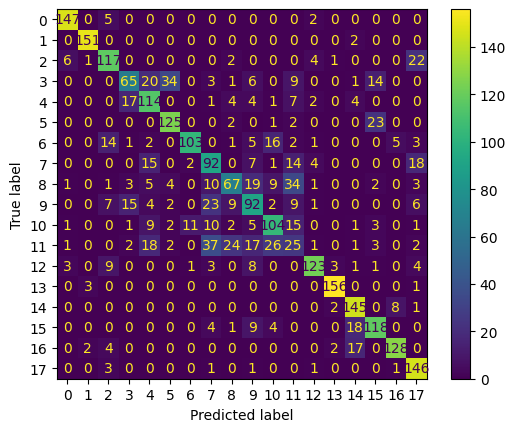

In [129]:
disp.plot()

In [130]:
print(classification_report(y_validation_inverse, classes_x))

              precision    recall  f1-score   support

           0       0.92      0.95      0.94       154
           1       0.96      0.99      0.97       153
           2       0.73      0.76      0.75       153
           3       0.62      0.42      0.51       153
           4       0.61      0.74      0.67       154
           5       0.74      0.82      0.78       153
           6       0.88      0.67      0.76       153
           7       0.50      0.60      0.55       153
           8       0.59      0.42      0.49       159
           9       0.53      0.54      0.54       170
          10       0.63      0.63      0.63       165
          11       0.21      0.16      0.18       159
          12       0.88      0.79      0.83       156
          13       0.95      0.97      0.96       160
          14       0.76      0.93      0.84       156
          15       0.72      0.77      0.74       154
          16       0.90      0.84      0.87       153
          17       0.71    

In [131]:
print(segments_test)

[[[ 7.09162521e+00 -5.91667116e-01  8.19550228e+00  3.14944088e-01
   -1.02227652e+00 -3.09961587e-01]
  [ 4.97275686e+00 -1.58316582e-01  6.69673157e+00  3.87382090e-01
   -6.18541241e-01 -4.89718020e-02]
  [ 3.25372005e+00 -1.91835418e-01  6.10775805e+00  7.09985420e-02
   -2.09479719e-01 -1.95978299e-01]
  ...
  [ 6.21534777e+00  9.38227773e-01 -2.54967523e+00 -1.22663522e+00
    3.00887406e-01 -8.98014963e-01]
  [ 7.78354979e+00  9.27753188e-03 -2.22645783e+00 -1.22770047e+00
   -7.36680150e-01 -3.91058278e+00]
  [ 1.07667246e+01 -2.13592720e+00 -3.58980626e-01 -7.20634580e-01
   -1.95427740e+00 -6.35110331e+00]]

 [[ 1.76620255e+01 -2.97389770e+00 -2.58424133e-01  1.16275287e+00
   -1.16811228e+00 -6.79957962e+00]
  [ 1.51337490e+01 -3.26838470e+00 -2.56029934e-01  2.36011004e+00
   -1.30659664e+00 -5.71087933e+00]
  [ 9.21767616e+00 -8.04751039e-01 -8.71339798e-01  2.57422829e+00
   -1.79874873e+00 -3.72309613e+00]
  ...
  [ 8.31266785e+00 -4.50409204e-01 -5.55305183e-01  2.22372

In [132]:
print(labels_test_categorical.shape)

(1535, 18)


In [133]:
print(labels_test_categorical)

[[1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]]


In [134]:
loss_test, accuracy_test = best_model.evaluate(segments_test, labels_test_categorical)

48/48 [==============================] - 4s 87ms/step - loss: 1.0208 - accuracy: 0.7472


In [135]:
predictions_test = best_model.predict(segments_test)

48/48 [==============================] - 4s 84ms/step


In [136]:
print(predictions_test)

[[9.6263438e-01 5.8074929e-06 3.6850289e-02 ... 1.0694819e-06
  5.4358970e-05 6.7689648e-06]
 [9.9173647e-01 5.0493754e-06 7.5006294e-03 ... 4.7113468e-07
  1.0055528e-05 6.1689281e-07]
 [9.9455762e-01 2.6999912e-06 5.0581936e-03 ... 3.0733332e-07
  5.7322686e-06 3.0916942e-07]
 ...
 [5.0957086e-03 2.2229836e-04 1.8417051e-01 ... 8.2056806e-04
  4.8158411e-02 5.7387304e-01]
 [3.3628754e-04 1.7678876e-04 6.0143240e-04 ... 7.2340532e-05
  2.5500028e-04 2.2804616e-01]
 [8.9862081e-04 2.3712947e-04 4.4966578e-02 ... 3.0652469e-04
  3.0406096e-03 2.7201968e-01]]


In [137]:
classes_x_test=np.argmax(predictions_test,axis=1)

In [138]:
print(classes_x_test)

[ 0  0  0 ... 17 14 14]


In [139]:
labels_test_argmax = np.argmax(labels_test_categorical,axis=1)

In [140]:
print(labels_test_argmax)

[ 0  0  0 ... 17 17 17]


In [141]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm_test = confusion_matrix(labels_test_argmax, classes_x_test)

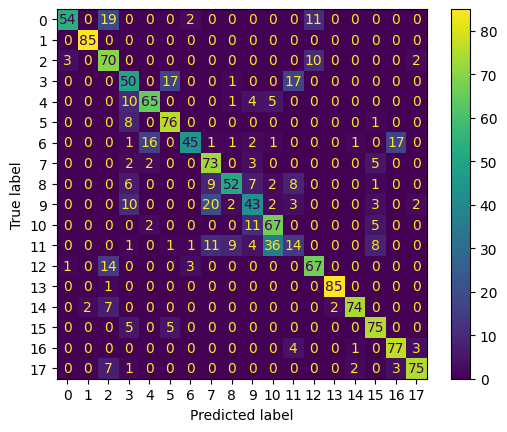

In [142]:
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test)
disp_test.plot()

In [143]:
print(classification_report(labels_test_argmax, classes_x_test))

              precision    recall  f1-score   support

           0       0.93      0.63      0.75        86
           1       0.98      1.00      0.99        85
           2       0.59      0.82      0.69        85
           3       0.53      0.59      0.56        85
           4       0.76      0.76      0.76        85
           5       0.77      0.89      0.83        85
           6       0.88      0.53      0.66        85
           7       0.64      0.86      0.73        85
           8       0.79      0.61      0.69        85
           9       0.58      0.51      0.54        85
          10       0.59      0.79      0.68        85
          11       0.30      0.16      0.21        85
          12       0.76      0.79      0.77        85
          13       0.98      0.99      0.98        86
          14       0.95      0.87      0.91        85
          15       0.77      0.88      0.82        85
          16       0.79      0.91      0.85        85
          17       0.91    

In [144]:
best_model.save(WORKDIR+"/Model/best_models_saved_"+data_hora)

INFO:tensorflow:Assets written to: C:/Users/cristiano.nascimento/git/LSTM_giroscopio_acelerometro/Model/best_models_saved_2024-04-04_22-21-08\assets


INFO:tensorflow:Assets written to: C:/Users/cristiano.nascimento/git/LSTM_giroscopio_acelerometro/Model/best_models_saved_2024-04-04_22-21-08\assets
